# Multilabel classification using a classifier chain: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/multioutput/plot_classifier_chain_yeast.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/multioutput/plot_classifier_chain_yeast.html)).

**Scenario:** an independent one-classifier-per-label model is compared with ten `ClassifierChain`s that use
random label orders (`order="random", random_state=i`) and with the ensemble that averages the chains'
`predict_proba`. Models are compared by samples-averaged Jaccard similarity.

**Adaptations**
- Data: the example downloads OpenML *yeast* (2417 samples, 103 features, 14 labels). The network is not used:
  `make_multilabel_classification(n_samples=600, n_features=30, n_classes=8, n_labels=3,
  allow_unlabeled=False, random_state=0)` stands in, split with the example's
  `train_test_split(test_size=0.2, random_state=0)`.
- Base estimator: the example uses `LogisticRegression`, which Moxie does not implement (GAP below). Section 1
  still runs the official code with `LogisticRegression` on the substituted data. The comparison (sections 2-3)
  uses `RandomForestClassifier(n_estimators=20, random_state=0)` on both sides: it has `predict_proba`, and
  Moxie's forests reproduce scikit-learn's integer-seeded draws.
- Independent model: the example uses `OneVsRestClassifier`; with a binary indicator target it fits one clone
  per label, exactly like `MultiOutputClassifier`, which Moxie's side uses. scikit-learn's `MultiOutputClassifier`
  is also checked to give the same predictions.
- `order="random"` is spelled `random_order=True` in Moxie (documented typed-parameter difference).
- Moxie forests take Float32 features and Float64 labels (`ClassifierChain[RandomForestClassifier[], DType.float32,
  DType.float64]`); probabilities are Float64, as in scikit-learn.

**Determinism:** deterministic: every forest and every chain order has an integer seed.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("multioutput/plot_classifier_chain_yeast")

## 1. scikit-learn: the official code (LogisticRegression) on the substituted data

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_multilabel_classification
from sklearn.model_selection import train_test_split

X, Y = make_multilabel_classification(n_samples=600, n_features=30, n_classes=8, n_labels=3,
                                      allow_unlabeled=False, random_state=0)
X = X.astype(np.float64)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import jaccard_score
from sklearn.multiclass import OneVsRestClassifier

base_lr = LogisticRegression(max_iter=2000)  # max_iter raised: unscaled count features
ovr = OneVsRestClassifier(base_lr)
ovr.fit(X_train, Y_train)
Y_pred_ovr = ovr.predict(X_test)
ovr_jaccard_score = jaccard_score(Y_test, Y_pred_ovr, average="samples")

from sklearn.multioutput import ClassifierChain

chains = [ClassifierChain(base_lr, order="random", random_state=i) for i in range(10)]
for chain in chains:
    chain.fit(X_train, Y_train)
Y_pred_chains = np.array([chain.predict_proba(X_test) for chain in chains])
chain_jaccard_scores = [
    jaccard_score(Y_test, Y_pred_chain >= 0.5, average="samples") for Y_pred_chain in Y_pred_chains
]
Y_pred_ensemble = Y_pred_chains.mean(axis=0)
ensemble_jaccard_score = jaccard_score(Y_test, Y_pred_ensemble >= 0.5, average="samples")
lr_scores = [ovr_jaccard_score] + chain_jaccard_scores + [ensemble_jaccard_score]
print("LogisticRegression Jaccard (independent, chains..., ensemble):", np.round(lr_scores, 3))
nb.note("LogisticRegression base estimator", "GAP",
        "moxie.linear_model has no LogisticRegression; the comparison below substitutes RandomForestClassifier")

LogisticRegression Jaccard (independent, chains..., ensemble): [0.487 0.494 0.488 0.477 0.465 0.489 0.49  0.485 0.477 0.486 0.486 0.484]


## 2. scikit-learn with the substituted base estimator

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier

base_rf = RandomForestClassifier(n_estimators=20, random_state=0)
ovr_rf = OneVsRestClassifier(base_rf).fit(X_train, Y_train)
sk_independent = ovr_rf.predict(X_test)
assert np.array_equal(sk_independent, MultiOutputClassifier(base_rf).fit(X_train, Y_train).predict(X_test))

rf_chains = [ClassifierChain(base_rf, order="random", random_state=i).fit(X_train, Y_train) for i in range(10)]
sk_orders = np.array([chain.order_ for chain in rf_chains])
sk_chain_proba = np.array([chain.predict_proba(X_test) for chain in rf_chains])
sk_chain_pred = np.array([chain.predict(X_test) for chain in rf_chains])

def jaccards(independent, chain_proba):
    chain_scores = [jaccard_score(Y_test, p >= 0.5, average="samples") for p in chain_proba]
    ensemble = jaccard_score(Y_test, chain_proba.mean(axis=0) >= 0.5, average="samples")
    return np.array([jaccard_score(Y_test, independent, average="samples")] + chain_scores + [ensemble])

sk_scores = jaccards(sk_independent, sk_chain_proba)
print("RandomForest Jaccard (independent, chains..., ensemble):", np.round(sk_scores, 3))
nb.share(X_train=X_train, Y_train=Y_train.astype(np.float64), X_test=X_test)

RandomForest Jaccard (independent, chains..., ensemble): [0.423 0.434 0.474 0.466 0.434 0.444 0.479 0.419 0.411 0.435 0.432 0.472]


## 3. Moxie (native Mojo)

`MultiOutputClassifier` and ten `ClassifierChain`s around `moxie.ensemble.RandomForestClassifier`.
Python only supplies the arrays and later computes the Jaccard metric from the saved predictions.

In [4]:
%%mojo classifier_chains
import numojo as nm
from numojo import Shape
from moxie.ensemble import RandomForestClassifier
from moxie.multioutput import MultiOutputClassifier, ClassifierChain
from moxie_nb_io import load, save, save_ints

comptime Forest = RandomForestClassifier[]


def main() raises:
    var X_train = load[DType.float32]("X_train")
    var Y_train = load("Y_train")
    var X_test = load[DType.float32]("X_test")

    var independent = MultiOutputClassifier[Forest, DType.float32, DType.float64](
        Forest(20, random_state=0))
    _ = independent.fit(X_train, Y_train)
    save("independent", independent.predict(X_test))

    var orders = List[Int]()
    for i in range(10):
        var chain = ClassifierChain[Forest, DType.float32, DType.float64](
            Forest(20, random_state=0), random_order=True, random_state=i)
        _ = chain.fit(X_train, Y_train)
        for j in range(len(chain.order_)):
            orders.append(chain.order_[j])
        save("proba_" + String(i), chain.predict_proba(X_test))
        save("pred_" + String(i), chain.predict(X_test))
    save_ints("orders", orders)
    print("fitted", len(independent.estimators_), "independent forests and 10 chains")

fitted 8 independent forests and 10 chains


## 4. Side by side and parity

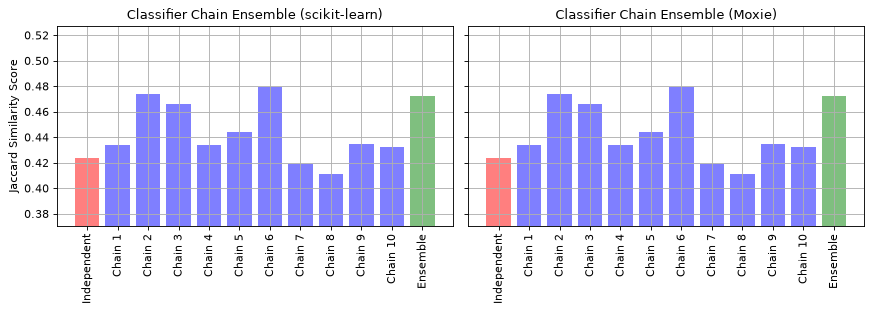

True

In [5]:
mx = nb.results["classifier_chains"]
mx_chain_proba = np.array([mx[f"proba_{i}"] for i in range(10)])
mx_chain_pred = np.array([mx[f"pred_{i}"] for i in range(10)])
mx_scores = jaccards(mx["independent"].astype(int), mx_chain_proba)

model_names = ("Independent",) + tuple(f"Chain {i}" for i in range(1, 11)) + ("Ensemble",)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=80, sharey=True)
for ax, scores, title in [(axes[0], sk_scores, "scikit-learn"), (axes[1], mx_scores, "Moxie")]:
    x_pos = np.arange(len(model_names))
    ax.grid(True)
    ax.set_title(f"Classifier Chain Ensemble ({title})")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(model_names, rotation="vertical")
    ax.set_ylim([min(sk_scores) * 0.9, max(sk_scores) * 1.1])
    ax.bar(x_pos, scores, alpha=0.5, color=["r"] + ["b"] * 10 + ["g"])
axes[0].set_ylabel("Jaccard Similarity Score")
plt.tight_layout()
plt.show()

moxie_nb.side_by_side(sklearn=np.round(sk_scores, 4), moxie=np.round(mx_scores, 4))
nb.compare("chain order_ (random_state=0..9)", sk_orders.ravel(), mx["orders"], exact=True)
nb.compare("independent predict", sk_independent.astype(np.float64), mx["independent"], exact=True)
nb.compare("chain predict (10 chains)", sk_chain_pred, mx_chain_pred, exact=True)
nb.compare("chain predict_proba (10 chains)", sk_chain_proba, mx_chain_proba, exact=True)
nb.compare("Jaccard scores (independent, chains, ensemble)", sk_scores, mx_scores, exact=True)

## 5. Unsupported: probability chains need a probabilistic NDArray component

`ClassifierChain.predict_proba` exists only when the component has `predict_proba`. With Moxie's
`RidgeClassifier` (the available linear classifier, no `predict_proba`) the call is rejected at compile time
instead of returning placeholder probabilities. This is why the comparison above substitutes a forest for the
example's `LogisticRegression`.

In [6]:
%%mojo ridge_chain_proba --expect-fail
import numojo as nm
from numojo import Shape
from moxie.linear_model import RidgeClassifier
from moxie.multioutput import ClassifierChain


def main() raises:
    var X = nm.zeros[DType.float64](Shape(4, 2))
    var Y = nm.zeros[DType.int64](Shape(4, 2))
    var chain = ClassifierChain(RidgeClassifier())
    _ = chain.fit(X, Y)
    print(chain.predict_proba(X))

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/multioutput/plot_classifier_chain_yeast/ridge_chain_proba.mojo:12:16: error: invalid call to 'predict_proba': violated constraint
    print(chain.predict_proba(X))
          ~~~~~^~~~~~~~~~~~~~
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/multioutput/plot_classifier_chain_yeast/ridge_chain_proba.mojo:4:
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps/moxie/multioutput.mojo:882:83: note: constraint declared here evaluated to False, expected 'conforms_to(E, ProbabilityPredictor)'
    def predict_proba(self, X: Self.Input) raises -> NDArray[DType.float64] where conforms_to(Self.E, ProbabilityPredictor):
                                                                                  ^
Imported from /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/multio

In [7]:
nb.note("ClassifierChain(RidgeClassifier()).predict_proba", "GAP",
        "compile-time rejection: RidgeClassifier has no predict_proba (sklearn raises AttributeError too); "
        "a LogisticRegression port is needed for the official example")
nb.note("order='random'", "ADAPTED", "random_order=True with integer random_state; orders match exactly")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
LogisticRegression base estimator,GAP,,,,,,moxie.linear_model has no LogisticRegression; the comparison below substitutes RandomForestClassifier,
chain order_ (random_state=0..9),PASS,"(80,)","(80,)",,,exact,0 mismatches,
independent predict,PASS,"(120, 8)","(120, 8)",,,exact,0 mismatches,
chain predict (10 chains),PASS,"(10, 120, 8)","(10, 120, 8)",,,exact,0 mismatches,
chain predict_proba (10 chains),PASS,"(10, 120, 8)","(10, 120, 8)",,,exact,0 mismatches,
"Jaccard scores (independent, chains, ensemble)",PASS,"(12,)","(12,)",,,exact,0 mismatches,
ClassifierChain(RidgeClassifier()).predict_proba,GAP,,,,,,compile-time rejection: RidgeClassifier has no predict_proba (sklearn raises AttributeError too); a LogisticRegression port is needed for the official example,
order='random',ADAPTED,,,,,,random_order=True with integer random_state; orders match exactly,
